# Basisrente: What the Contract Yields, and the Same Money in an ETF

A real contract, modelled month by month: the NÜRNBERGER Fondsgebundene
Basisrente (tariff NFX3208T) signed in October 2024 — 500 € a month from
November 2024, 468 contributions, a lifelong pension from 1 November 2063, at
67. The documents stay out of git (`data/ruerp/`); the figures used here are
copied from them and pinned in
[`tests/test_ruerup.py`](../tests/test_ruerup.py), where the model reproduces
the insurer's year-by-year contract values to within 20 € in the early years
and 0.015% after four decades.

Three questions:

1. **What does the contract yield?** Capital and pension at 67 across market
   returns, the guaranteed annuity factor against the current one, and where
   the costs go.
2. **Rürup against an ETF.** Two worlds with the same gross outlay: the
   contract, with its tax refunds invested, or the same 500 € a month in a
   broad ETF. Both run in the engine from the first contribution to the month
   you turn 100, retirement included: the salaries stop, the statutory
   pensions start, health insurance and tax are a retiree's. At 67 the ETF
   world holds more liquid capital and the Rürup world a pension for life. The
   *break-even age* is when the Rürup world's wealth catches up — beyond it the
   Rürup wins, before it the ETF does.
3. **How much to contribute?** A top-up from 2026, booked as a second contract
   the way the insurer books an Erhöhung, from 250 € a month to the
   deduction cap and beyond.

These are model results under stated assumptions, not advice: they move with
the market return, the tax rate in old age and how long one lives.

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().resolve().parent
sys.path.append(str(ROOT_DIR))

import pandas as pd
from matplotlib import pyplot as plt

from src.model import (
    Earner,
    Etf,
    FinancialModel,
    GermanHousehold,
    PrivateHealthInsurance,
    Retirement,
    RuerupAnnuity,
    RuerupCosts,
    RuerupPension,
)
from src.model.german_tax import RENTENWERT, TaxSystem, basisrente_cap, social_contributions

## Assumptions

**The contract** (signed version): 500 € a month for 468 months, 14 of them
paid before the model starts in January 2026. The tariff's own costs —
2.5% acquisition cost on the 234,000 € contribution sum spread over five
years, 4.5% of every contribution, 0.40% a year on the capital — are the
`RuerupCosts` defaults. The five funds cost about 0.38% a year on top: that is
what reconciles the tariff with the PIB's gross-return examples.

**The pension**: the guaranteed Rentenfaktor is 21.246830 € a month per
10,000 €. The insurer illustrates 24.996271 € (its 2024 basis) plus a
Zusatzrente of 1.87% of the capital a year — nearly twice the guarantee, and
neither part promised.

**The ETF**: a broad world ETF at 0.20% TER, taxed at the Abgeltungsteuer
with Soli on 70% of the gain (Teilfreistellung) — on every sale, the ones
that pay the household's bills included. The Sparerpauschbetrag and the
Vorabpauschale are left out. Both products see the same market return, each
less its own fund costs.

**Old age**: you stop working when the contract stops, at the end of October
2063, and draw the Regelaltersrente from November; your spouse retires in
mid-2059, at 67 too. Both statutory pensions follow wages, before they start
and after. You keep your private health insurance, and the pension fund pays
half the health premium up to its KVdR share; your spouse joins the
Krankenversicherung der Rentner. Nothing is withheld from a pension, so each
year's tax is paid with the next July's settlement. The tariff borders keep
drifting at 2.5% a year for all seventy years, the 45% border included.

**Placeholders** until the documents arrive: the second salary (80,000 €
with statutory insurance, as in the insurer's tax illustration), the
statutory pensions (the insurer's own estimate, turned back into
Entgeltpunkte and valued at today's Rentenwert), and your spouse's
retirement date.

In [2]:
SYSTEM = TaxSystem(rich_threshold_frozen=False)  # 2026 law, drifting by inertia for 70 years
MONTHLY = 500.0
TERM = 468                          # contributions Nov 2024 – Oct 2063
ELAPSED = 14                        # paid before the model starts in January 2026
START_AGE = 67

GUARANTEED = RuerupAnnuity()                                   # 21.246830 € per 10,000 €
DECLARED = RuerupAnnuity(factor=24.996271, bonus_rate=0.0187)  # 2024 basis, not promised

FUND_COSTS = 0.0038                 # the five funds' own costs
ETF_TER = 0.0020
ETF_TAX = 0.26375 * 0.7             # Abgeltungsteuer + Soli with 30% Teilfreistellung
INFLATION = 0.02
WAGE_GROWTH = SYSTEM.yearly_wage_growth   # salaries, and the statutory pensions after them

# The insurer's estimate: 9,882 € and 8,524 € a month in 2063 at its
# fictitious Rentenwert of 124.53 € — in Entgeltpunkte, valued at today's 40.79 €.
YOUR_POINTS = 9_882 / 124.53
SPOUSE_POINTS = 8_524 / 124.53
SPOUSE_EARLIER = 52                 # months: your spouse's pension starts in mid-2059


def fund_return(market: float, costs: float) -> float:
    # A fund's own growth: the market return less the fund's costs.
    return (1.0 + market) * (1.0 - costs) - 1.0


def contract(market: float, **changes) -> RuerupPension:
    return RuerupPension(
        monthly_contribution=MONTHLY,
        contribution_months=TERM,
        yearly_return_rate=fund_return(market, FUND_COSTS),
        **changes,
    )


statutory = (YOUR_POINTS + SPOUSE_POINTS) * RENTENWERT
print(f"Statutory pensions, both of you, in today's money: €{statutory:,.0f} a month")

Statutory pensions, both of you, in today's money: €6,029 a month


## 1. What the Contract Yields

First the model against the insurer. The signed contract tabulates its value
at every anniversary for a fund growth — after the funds' costs — of 0, 3, 7
and 9% a year; a few of those years, insurer against model:

In [3]:
INSURER = {  # contract value at the anniversary, from the signed contract
    0.00: {1: 4_549, 5: 22_570, 10: 50_493, 20: 104_691, 30: 156_764, 39: 201_881},
    0.03: {1: 4_611, 5: 24_288, 10: 58_127, 20: 140_273, 30: 246_341, 39: 367_974},
    0.07: {1: 4_693, 5: 26_767, 10: 70_443, 20: 213_037, 30: 482_541, 39: 925_194},
    0.09: {1: 4_733, 5: 28_092, 10: 77_678, 20: 265_247, 30: 691_876, 39: 1_525_634},
}

table = {}
worst = 0.0
for growth, values in INSURER.items():
    model = RuerupPension(
        monthly_contribution=MONTHLY, contribution_months=TERM, yearly_return_rate=growth
    ).contract_values()
    column = {}
    for year, insurer in values.items():
        ours = model[12 * year - 1]
        worst = max(worst, abs(ours / insurer - 1.0))
        column[year] = f"€{insurer:>9,} / €{ours:>9,.0f}"
    table[f"{growth:.0%} (insurer / model)"] = column
print(f"Largest deviation in this table: {worst * 100:.3f}%")
pd.DataFrame(table).rename_axis("year")

Largest deviation in this table: 0.071%


,0% (insurer / model),3% (insurer / model),7% (insurer / model),9% (insurer / model)
year,,,,
1,"€ 4,549 / € 4,552","€ 4,611 / € 4,614","€ 4,693 / € 4,696","€ 4,733 / € 4,736"
5,"€ 22,570 / € 22,577","€ 24,288 / € 24,295","€ 26,767 / € 26,775","€ 28,092 / € 28,101"
10,"€ 50,493 / € 50,500","€ 58,127 / € 58,135","€ 70,443 / € 70,455","€ 77,678 / € 77,691"
20,"€ 104,691 / € 104,698","€ 140,273 / € 140,284","€ 213,037 / € 213,059","€ 265,247 / € 265,276"
30,"€ 156,764 / € 156,770","€ 246,341 / € 246,355","€ 482,541 / € 482,581","€ 691,876 / € 691,942"
39,"€ 201,881 / € 201,887","€ 367,974 / € 367,991","€ 925,194 / € 925,264","€1,525,634 / €1,525,773"


Now with a market return instead of a fund growth: the five funds keep 0.38% a
year for themselves before the tariff's costs start. The pension starts in
November 2063; "today's money" deflates it by 2% a year back to 2026.

In [4]:
YEARS_TO_PENSION = (TERM - ELAPSED) / 12
DEFLATOR = (1.0 + INFLATION) ** YEARS_TO_PENSION

rows = []
for market in (0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08):
    capital = contract(market).capital_at_pension_start()
    declared = DECLARED.monthly_pension(capital)
    rows.append(
        {
            "market return": f"{market:.0%}",
            "capital at 67": f"€{capital:,.0f}",
            "pension, guaranteed": f"€{GUARANTEED.monthly_pension(capital):,.0f}",
            "pension, 2024 basis": f"€{declared:,.0f}",
            "2024 basis, today's €": f"€{declared / DEFLATOR:,.0f}",
        }
    )
pd.DataFrame(rows)

,market return,capital at 67,"pension, guaranteed","pension, 2024 basis","2024 basis, today's €"
0,2%,"€276,104",€587,"€1,120",€530
1,3%,"€339,331",€721,"€1,377",€651
2,4%,"€420,864",€894,"€1,708",€807
3,5%,"€526,447","€1,119","€2,136","€1,010"
4,6%,"€663,669","€1,410","€2,693","€1,273"
5,7%,"€842,570","€1,790","€3,419","€1,616"
6,8%,"€1,076,425","€2,287","€4,368","€2,065"


### Where the costs go

At a 5% market return, starting from a contract that cost nothing and adding
one cost layer at a time. Each figure is what that layer takes from the
capital at 67, compounded — larger than the euros it charges, because a euro
charged early would have kept growing.

In [5]:
MARKET = 0.05


def capital_with(costs: RuerupCosts, fund_costs: float) -> float:
    return RuerupPension(
        monthly_contribution=MONTHLY,
        contribution_months=TERM,
        yearly_return_rate=fund_return(MARKET, fund_costs),
        costs=costs,
    ).capital_at_pension_start()


steps = [
    ("no costs at all", capital_with(RuerupCosts(0.0, 60, 0.0, 0.0), 0.0)),
    ("+ 2.5% acquisition cost, over 5 years", capital_with(RuerupCosts(0.025, 60, 0.0, 0.0), 0.0)),
    ("+ 4.5% of every contribution", capital_with(RuerupCosts(0.025, 60, 0.045, 0.0), 0.0)),
    ("+ 0.40% a year on the capital", capital_with(RuerupCosts(), 0.0)),
    ("+ the funds' own 0.38% a year", capital_with(RuerupCosts(), FUND_COSTS)),
]
pd.DataFrame(
    [
        {
            "": label,
            "capital at 67": f"€{value:,.0f}",
            "this layer takes": "" if index == 0 else f"€{steps[index - 1][1] - value:,.0f}",
        }
        for index, (label, value) in enumerate(steps)
    ]
)

,,capital at 67,this layer takes
0,no costs at all,"€702,972",
1,"+ 2.5% acquisition cost, over 5 years","€668,097","€34,876"
2,+ 4.5% of every contribution,"€636,463","€31,634"
3,+ 0.40% a year on the capital,"€577,109","€59,354"
4,+ the funds' own 0.38% a year,"€526,447","€50,662"


In [6]:
def effective_return(capital: float) -> float:
    # The yearly return that turns the contributions into `capital` with no cost at all.
    low, high = -0.05, 0.20
    for _ in range(100):
        guess = (low + high) / 2.0
        rate = (1.0 + guess) ** (1.0 / 12.0) - 1.0
        value = 0.0
        for _ in range(TERM):
            value = value * (1.0 + rate) + MONTHLY
        value *= 1.0 + rate
        low, high = (guess, high) if value < capital else (low, guess)
    return guess


after_costs = effective_return(steps[-1][1])
print(f"Paid in over 39 years:   €{MONTHLY * TERM:,.0f}")
print(f"Capital at 67, at {MARKET:.0%}:   €{steps[-1][1]:,.0f}")
print(f"Effective return:        {after_costs * 100:.2f}% a year, "
      f"{(MARKET - after_costs) * 100:.2f} points of costs (the PIB states 1.23)")

Paid in over 39 years:   €234,000
Capital at 67, at 5%:   €526,447
Effective return:        3.78% a year, 1.22 points of costs (the PIB states 1.23)


## 2. Rürup against an ETF

The same household in two worlds, with the same gross outlay. In one it pays
500 € a month into the contract; the tax that saves comes back every July and
goes into the ETF. In the other the 500 € go straight into the ETF. You earn
100,000 € and are privately insured (the May 2026 payslip); your spouse earns
80,000 € with statutory insurance (the placeholder). Both salaries grow with
wages; Steuerklasse IV/IV. Everything else is shared and cancels out.

This is a comparison of the product, so both worlds start with the contract,
39 years before the pension. The calendar is shifted by 14 months, which lets
2026 law apply from the first year.

Both worlds then run on in the engine, through retirement, to the month you
turn 100. The pensions arrive; your spouse pays the KVdR share out of theirs,
you keep paying the private premium, less the pension fund's subsidy; every
pension is taxed with those contributions deducted, and the tax is paid with
the next July's settlement — by selling ETF shares, which costs the ETF's own
tax on the gains a sale realizes. The Rürup world's pension joins its ETF.
Each world's *wealth* is its ETF after the tax a sale would cost, plus the
settlement still due; the break-even age is when the two meet.

In [7]:
YEARS = TERM // 12 + 33          # to the month you turn 100
AT_67 = TERM // 12               # the year-39 row: you are 67, the pension starts next month


def household(working_months: int, *, statutory_share: float = 1.0, law: TaxSystem = SYSTEM) -> GermanHousehold:
    # You retire after `working_months`, your spouse SPOUSE_EARLIER months before.
    return GermanHousehold(
        earners=(
            Earner(
                monthly_gross=100_000 / 12,
                yearly_increase_rate=WAGE_GROWTH,
                private_health=PrivateHealthInsurance(
                    monthly_premium=638.0,
                    monthly_care_premium=57.0,
                    deductible_share=349.0 / 638.0,
                    monthly_rebate=182.95,
                ),
                retirement=Retirement.from_entgeltpunkte(
                    YOUR_POINTS * statutory_share, working_months=working_months
                ),
            ),
            Earner(
                monthly_gross=80_000 / 12,
                yearly_increase_rate=WAGE_GROWTH,
                retirement=Retirement.from_entgeltpunkte(
                    SPOUSE_POINTS * statutory_share, working_months=working_months - SPOUSE_EARLIER
                ),
            ),
        ),
        tax_classes="IV/IV",
        tax=law,
    )


def etf(market: float) -> Etf:
    return Etf(yearly_return_rate=fund_return(market, ETF_TER), tax_rate=ETF_TAX)


def run(*components, years: int = YEARS, at_67: int = AT_67) -> pd.DataFrame:
    model = FinancialModel(list(components), years=years, start_age=START_AGE - at_67)
    return model.run().set_index("year")


def wealth(frame: pd.DataFrame) -> pd.Series:
    # The ETF after the tax a sale would cost, plus the settlement due next July.
    pending = frame["household.yearly_withheld_tax"] - frame["household.yearly_assessed_tax"]
    return frame["etf_capital_after_tax"] + pending


def break_even(with_contract: pd.DataFrame, without: pd.DataFrame, at_67: int = AT_67):
    # The age at which the Rürup world's wealth catches up, between two year ends.
    lead = wealth(without) - wealth(with_contract)
    if lead[at_67] <= 0.0:
        return float(START_AGE)
    for year in range(at_67 + 1, len(lead)):
        if lead[year] <= 0.0:
            before, after = lead[year - 1], lead[year]
            return with_contract.loc[year - 1, "age"] + before / (before - after)
    return None


def pension_and_tax(with_contract: pd.DataFrame, without: pd.DataFrame, year: int) -> tuple[float, float]:
    # The Rürup pension in `year` and the income tax it adds, yearly.
    tax = with_contract.loc[year, "household.yearly_assessed_tax"] - without.loc[year, "household.yearly_assessed_tax"]
    return with_contract.loc[year, "ruerup.yearly_pension"], tax


def age(value) -> str:
    return "after 100" if value is None else f"{value:.1f}"

In [8]:
worlds = {}
rows = []
for market in (0.03, 0.05, 0.07):
    without = run(household(TERM), etf(market))
    row = {"market return": f"{market:.0%}"}
    for label, annuity in (("guaranteed", GUARANTEED), ("2024 basis", DECLARED)):
        with_contract = run(household(TERM), contract(market, annuity=annuity), etf(market))
        worlds[market, label] = (with_contract, without)
        if label == "guaranteed":
            saved = without["household.yearly_assessed_tax"] - with_contract["household.yearly_assessed_tax"]
            refunds = saved.loc[1:AT_67].sum()
            row["tax refunds"] = f"€{refunds:,.0f} ({refunds / (MONTHLY * TERM):.0%})"
            row["Rürup capital at 67"] = f"€{with_contract.loc[AT_67 + 1, 'ruerup.pension_capital']:,.0f}"
            lead = wealth(without) - wealth(with_contract)
            row["extra ETF wealth at 67"] = f"€{lead[AT_67]:,.0f}"
        pension, tax = pension_and_tax(with_contract, without, AT_67 + 1)
        row[f"net pension, {label}"] = f"€{(pension - tax) / 12:,.0f}"
        row[f"break-even, {label}"] = age(break_even(with_contract, without))
    rows.append(row)
pd.DataFrame(rows).set_index("market return").T

market return,3%,5%,7%
tax refunds,"€109,461 (47%)","€109,461 (47%)","€109,461 (47%)"
Rürup capital at 67,"€339,331","€526,447","€842,570"
extra ETF wealth at 67,"€209,979","€325,101","€525,601"
"net pension, guaranteed",€479,€741,"€1,182"
"break-even, guaranteed",after 100,after 100,after 100
"net pension, 2024 basis",€911,"€1,407","€2,234"
"break-even, 2024 basis",95.3,after 100,after 100


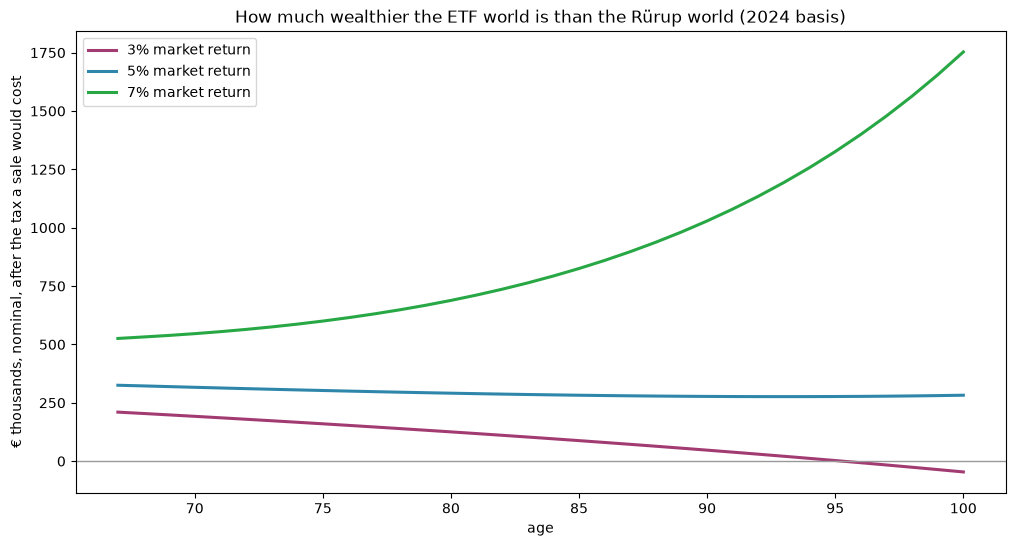

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
for market, color in ((0.03, "#A23B72"), (0.05, "#2E86AB"), (0.07, "#28A745")):
    with_contract, without = worlds[market, "2024 basis"]
    lead = (wealth(without) - wealth(with_contract)).loc[AT_67:]
    ages = with_contract.loc[AT_67:, "age"]
    ax.plot(ages, lead / 1000, color=color, lw=2.2, label=f"{market:.0%} market return")
ax.axhline(0, color="#999999", lw=1)
ax.set_title("How much wealthier the ETF world is than the Rürup world (2024 basis)")
ax.set_xlabel("age")
ax.set_ylabel("€ thousands, nominal, after the tax a sale would cost")
ax.legend()
plt.show()

### What moves the break-even age

The tax in old age is the least certain input. It depends on how large the
statutory pensions turn out to be, and on whether the tariff keeps up with
pensions: the inertia behind `TaxSystem` lets wages, and the pensions after
them, grow at 3.3% while the tariff borders move at 2.5%. Over four decades
that creep alone puts the pension into a higher bracket. Below, the
statutory pensions at the placeholder and at half of it, with the tariff
either creeping or moving with wages — for the whole seventy years, so the
refunds while you work move too — at the 2024 annuity basis throughout.
"Tax" is the share of the Rürup pension that the household's income tax
rises by in the first full year of your retirement.

In [10]:
indexed = TaxSystem(rich_threshold_frozen=False, yearly_threshold_growth=WAGE_GROWTH)
rows = []
for statutory_share in (1.0, 0.5):
    for law_label, law in (("tariff creeps (2.5%)", SYSTEM), ("tariff moves with wages", indexed)):
        row = {"statutory pensions": f"{statutory_share:.0%} of placeholder", "tariff": law_label}
        couple = household(TERM, statutory_share=statutory_share, law=law)
        for market in (0.03, 0.05, 0.07):
            without = run(couple, etf(market))
            with_contract = run(couple, contract(market, annuity=DECLARED), etf(market))
            pension, tax = pension_and_tax(with_contract, without, AT_67 + 1)
            reached = break_even(with_contract, without)
            row[f"{market:.0%}: tax / break-even"] = f"{tax / pension:.0%} / {age(reached)}"
        rows.append(row)
pd.DataFrame(rows)

,statutory pensions,tariff,3%: tax / break-even,5%: tax / break-even,7%: tax / break-even
0,100% of placeholder,tariff creeps (2.5%),34% / 95.3,34% / after 100,35% / after 100
1,100% of placeholder,tariff moves with wages,30% / 93.4,30% / after 100,30% / after 100
2,50% of placeholder,tariff creeps (2.5%),25% / 90.4,26% / after 100,26% / after 100
3,50% of placeholder,tariff moves with wages,21% / 89.3,22% / after 100,23% / after 100


### Against the previous, pure-function estimate

The previous version of this notebook (commit `001ea8f`) ran only the 39
years of contributions in the engine and priced old age outside it: the pure
tariff on the statutory pensions plus the Rürup, both of you retired from
67, no health contributions in old age, and the extra ETF capital paying
itself the Rürup's net pension, taxed as it was sold. Its figures against the
engine's, at the 2024 basis:

In [11]:
PREVIOUS = {  # printed by the previous version, 2024 basis
    0.03: dict(net=891, tax=0.35, capital=229_326, break_even=95.1),
    0.05: dict(net=1_376, tax=0.36, capital=370_514, break_even=None),
    0.07: dict(net=2_185, tax=0.36, capital=616_413, break_even=None),
}
rows = []
for market, previous in PREVIOUS.items():
    with_contract, without = worlds[market, "2024 basis"]
    pension, tax = pension_and_tax(with_contract, without, AT_67 + 1)
    # The previous gross measure: ETF capital, with the contract world's
    # refund still due added back as cash.
    pending = without.loc[AT_67, "household.yearly_assessed_tax"] - with_contract.loc[AT_67, "household.yearly_assessed_tax"]
    capital = without.loc[AT_67, "etf_capital"] - with_contract.loc[AT_67, "etf_capital"] - pending
    sale_tax = (with_contract["etf.yearly_sale_tax"] - without["etf.yearly_sale_tax"]).loc[AT_67 + 1 :].sum()
    rows.append(
        {
            "market return": f"{market:.0%}",
            "net pension": f"€{previous['net']:,} / €{(pension - tax) / 12:,.0f}",
            "tax on it": f"{previous['tax']:.0%} / {tax / pension:.0%}",
            "extra ETF capital at 67": f"€{previous['capital']:,} / €{capital:,.0f}",
            "extra Abgeltungsteuer on sales, 67 to 100": f"— / €{sale_tax:,.0f}",
            "break-even": f"{age(previous['break_even'])} / {age(break_even(with_contract, without))}",
        }
    )
pd.DataFrame(rows).set_index("market return").T.rename_axis("previous / engine")

market return,3%,5%,7%
previous / engine,,,
net pension,€891 / €911,"€1,376 / €1,407","€2,185 / €2,234"
tax on it,35% / 34%,36% / 34%,36% / 35%
extra ETF capital at 67,"€229,326 / €229,326","€370,514 / €370,514","€616,413 / €616,413"
"extra Abgeltungsteuer on sales, 67 to 100","— / €12,865","— / €32,591","— / €66,510"
break-even,95.1 / 95.3,after 100 / after 100,after 100 / after 100


Before 67 nothing moved. Your spouse retiring four years earlier leaves the
household in the 42% zone, so every contribution saves what it saved before,
and the extra ETF capital at 67 is the same to the euro. After 67 three
things differ, and they pull in opposite directions:

- **Health insurance in old age.** The engine deducts what you both pay for
  it as pensioners — your spouse's KVdR share, your basic private premium net
  of the pension fund's subsidy — before it taxes the pensions. The Rürup
  pension then costs one or two points less tax, and its net pension comes
  out about 2% higher.
- **When the tax is paid.** Nothing is withheld from a pension: a year's tax
  is paid with the next July's settlement, not as the pension arrives, and
  the money it waits in stays invested — a little in the Rürup world's
  favour, since it owes more.
- **How the tax is paid.** That July bill is paid by selling ETF shares, and
  the sales realize gains the ETF taxes. Owing more income tax, the Rürup
  world sells more and pays the Abgeltungsteuer on more: the row above, 13,000
  to 67,000 € more by 100.

At 3% the last one weighs most: the break-even moves from 95.1 to 95.3. At 5%
and 7% the ETF world stays ahead past 100 either way. The July sales are the
model's, not the household's — a real Finanzamt would ask for quarterly
Vorauszahlungen, paid out of the pensions — so this row is the price of the
simplification, and the break-even it moves is a little pessimistic for the
Rürup.

## 3. How Much to Contribute

Now on the real calendar: the contract is already running in both worlds, and
the question is a top-up from January 2026 to the end. The insurer books an
Erhöhung as a part of its own, with its own 2.5% acquisition cost on its own
contribution sum, ending with the main contract — so here it is a second
`RuerupPension`, starting at month zero and running the remaining 454 months.

The deduction cap is shared: 61,652 € for the couple in 2026, less both halves
of both statutory contributions, less the 6,000 € the contract already uses.
Above that a contribution saves nothing at all. Below it, every euro saves less
than the one before, because each pushes the taxable income down the tariff.

Both worlds run to the end of 2096, the year you turn 100, and both contracts
pay at the 2024 annuity basis. In old age the top-up's pension is taxed on top
of the statutory pensions *and* the main contract's.

In [12]:
REMAINING = TERM - ELAPSED   # January 2026 – October 2063: your salary months
REAL_YEARS = 71              # to December 2096, the year you turn 100
REAL_AT_67 = 38              # the year-38 row is December 2063

room = basisrente_cap(SYSTEM, joint=True) - 12.0 * MONTHLY
for gross, private in ((100_000.0, True), (80_000.0, False)):
    social = social_contributions(gross, SYSTEM, n_children=0, private_health=private)
    room -= 2.0 * social.pension
print(f"Deduction room left in 2026: €{room:,.0f} a year, €{room / 12:,.0f} a month")

markets = {}
for market in (0.03, 0.05):
    base = [household(REMAINING), contract(market, elapsed_months=ELAPSED, annuity=DECLARED), etf(market)]
    markets[market] = (base, run(*base, years=REAL_YEARS, at_67=REAL_AT_67))

rows = []
for top_up in (250, 500, 1_000, 1_500, round(room / 12), 2_500):
    row = {"top-up / month": f"€{top_up:,}"}
    for market, (base, without) in markets.items():
        extra = RuerupPension(
            monthly_contribution=float(top_up),
            contribution_months=REMAINING,
            yearly_return_rate=fund_return(market, FUND_COSTS),
            annuity=DECLARED,
            name="top_up",
        )
        with_top_up = run(*base, extra, years=REAL_YEARS, at_67=REAL_AT_67)
        saved = (
            without.loc[1, "household.yearly_assessed_tax"]
            - with_top_up.loc[1, "household.yearly_assessed_tax"]
        )
        row["tax saved in 2026, per €"] = f"{saved / (12.0 * top_up):.1%}"
        lead = wealth(without) - wealth(with_top_up)
        row[f"{market:.0%}: pension"] = f"€{DECLARED.monthly_pension(extra.capital_at_pension_start()):,.0f}"
        row[f"{market:.0%}: extra ETF wealth at 67"] = f"€{lead[REAL_AT_67]:,.0f}"
        row[f"{market:.0%}: break-even"] = age(break_even(with_top_up, without, REAL_AT_67))
    rows.append(row)
pd.DataFrame(rows).set_index("top-up / month")

Deduction room left in 2026: €22,172 a year, €1,848 a month


,"tax saved in 2026, per €",3%: pension,3%: extra ETF wealth at 67,3%: break-even,5%: pension,5%: extra ETF wealth at 67,5%: break-even
top-up / month,,,,,,,
€250,42.0%,€659,"€100,953",95.8,"€1,007","€154,592",after 100
€500,42.0%,"€1,317","€202,633",96.2,"€2,013","€310,349",after 100
"€1,000",41.7%,"€2,634","€408,010",96.8,"€4,026","€625,001",after 100
"€1,500",41.3%,"€3,952","€615,741",97.4,"€6,039","€943,483",after 100
"€1,848",40.9%,"€4,868","€761,601",97.8,"€7,440","€1,167,275",after 100
"€2,500",30.2%,"€6,586","€1,068,867",after 100,"€10,065","€1,648,988",after 100


## What This Leaves Out

- No Vorauszahlungen: each year's tax on the pensions is paid the next July,
  by selling ETF shares, and the Rürup world, owing more, sells more. A real
  Finanzamt would set quarterly prepayments, paid out of the pensions, and
  fewer shares would be sold.
- No Rentengarantiezeit: a death before 87 would pay the remaining guaranteed
  months to a surviving spouse, while the ETF world would leave its whole
  remaining capital.
- The pension stays flat; above a 3% Gesamtverzinsung the insurer would raise it
  a little each year.
- Returns are smooth. With volatile ones the kursorientiertes
  Ablaufmanagement in the contract would matter, and so would the order of
  good and bad years.
- Your private premium keeps rising at 3.5% a year for life; the drop at 65,
  when the contract's statutory 10% surcharge stops being charged, is not
  modelled, and your spouse is assumed to qualify for the KVdR.
- The placeholders: the second salary, both statutory pensions and your
  spouse's retirement date. Once the Renteninformation and the second payslip
  are in `data/ruerp/`, replace them.